# Διάλεξη 1 — Τι Μαθαίνουν οι Μηχανές

**Μάθημα:** Εισαγωγή στην Τεχνητή Νοημοσύνη  
**Lab:** Supervised ML · Confusion Matrix · Threshold · ROC  

---

## Πώς δουλεύει αυτό το notebook

Άλλαξε **μόνο** το **Knobs cell** παρακάτω. Όλα τα υπόλοιπα cells τρέχουν αυτόματα.

**Δύο datasets διαθέσιμα:**
| Dataset | Πρόβλημα | Positive class |
|---------|----------|----------------|
| `"breast_cancer"` | Ιατρική διάγνωση | Benign (καλοήθης) |
| `"euroleague"` | EuroLeague stats → starter; | is_starter = 1 |

> **Tip:** Τρέξε πρώτα με `breast_cancer`, μετά αλλαξε σε `euroleague` και παρατήρησε τι αλλάζει στα metrics!

In [105]:
# ╔══════════════════════════════════════════════════════════╗
# ║                  KNOBS — Άλλαξε μόνο εδώ                ║
# ╚══════════════════════════════════════════════════════════╝

# Επιλογή dataset: "breast_cancer" ή "euroleague"
DATASET          = "euroleague"

# Μοντέλο: "logreg" (Logistic Regression) ή "tree" (Decision Tree)
MODEL_NAME       = "tree"

# Threshold: τιμή αποκοπής (δοκίμασε 0.30 και 0.70)
THRESHOLD        = 0.70

# Test size: ποσοστό δεδομένων για αξιολόγηση
TEST_SIZE        = 0.20

# Για αναπαραγωγιμότητα
RANDOM_STATE     = 42

# ── Νέα knobs: Class Imbalance & Cross-Validation ────────────────────────
# class_weight: None = χωρίς διόρθωση | "balanced" = αυτόματη διόρθωση
USE_CLASS_WEIGHT = True

# Αριθμός folds για Cross-Validation (δοκίμασε 3, 5, 10)
N_CV_FOLDS       = 10

# ── EuroLeague settings ───────────────────────────────────────────────────
EUROLEAGUE_PATH   = "../euroleague_data/euroleague_players.csv"
EUROLEAGUE_SEASON = "E2024"   # None = όλες οι σεζόν
MIN_GAMES         = 10


---
## 0. Imports

In [106]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_breast_cancer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import (
    train_test_split, cross_val_score, learning_curve
)
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    confusion_matrix, precision_score, recall_score,
    f1_score, accuracy_score, roc_curve, roc_auc_score
)
import warnings
warnings.filterwarnings("ignore")


# ── Colour palette (used throughout the notebook) ─────────────────────────
C_PLOT = {
    "navy":   "#1E2761",
    "blue":   "#2D6A9F",
    "accent": "#F96167",
    "yellow": "#FFC857",
    "light":  "#EAF0FB",
    "teal":   "#0D9488",
    "white":  "#FFFFFF",
    "dark":   "#1A1A2E",
    "gray":   "#6B7280",
}
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.dpi"] = 110
print(f"✅ Imports OK | Dataset: {DATASET} | Μοντέλο: {MODEL_NAME} | Threshold: {THRESHOLD}")
print(f"   class_weight: {'balanced' if USE_CLASS_WEIGHT else 'None'} | CV folds: {N_CV_FOLDS}")


✅ Imports OK | Dataset: euroleague | Μοντέλο: tree | Threshold: 0.7
   class_weight: balanced | CV folds: 10


---
## 1. Φόρτωση Dataset

Ανάλογα με το `DATASET` knob, φορτώνουμε διαφορετικά δεδομένα.  
Το **context** αλλάζει — και μαζί του η σημασία του FP και FN!

In [107]:
def load_breast_cancer_data():
    bc = load_breast_cancer()
    X = pd.DataFrame(bc.data, columns=bc.feature_names)
    y = pd.Series(bc.target, name="target")  # 0=malignant, 1=benign
    context = {
        "name":           "Breast Cancer Wisconsin",
        "target_names":   ["Malignant (κακοήθης)", "Benign (καλοήθης)"],
        "positive_label": "Benign",
        "fn_meaning":     "Είπαμε 'καλοήθης' σε κακοήθη όγκο — ο ασθενής ΔΕΝ θεραπεύεται!",
        "fp_meaning":     "Είπαμε 'κακοήθης' σε καλοήθη — ανησυχία & επιπλέον εξετάσεις",
        "fn_cost":        "ΠΟΛΥ ΥΨΗΛΟ — κίνδυνος ζωής",
        "fp_cost":        "ΜΕΤΡΙΟ — ψυχολογικό κόστος",
        "strategy":       "Χαμηλό threshold (0.30) → ↑ Recall → λιγότερα FN",
        "key_metric":     "Recall",
    }
    return X, y, context


def load_euroleague_data():
    df = pd.read_csv("euroleague.csv")
    if EUROLEAGUE_SEASON:
        df = df[df["season_code"] == EUROLEAGUE_SEASON].copy()
    df = df[df["games_played"] >= MIN_GAMES].copy()

    # Binary target: is_starter
    df["is_starter"] = (df["games_started"] / df["games_played"] > 0.5).astype(int)

    # Per-game features
    feature_cols = [
        "valuation_per_game", "points_per_game", "assists_per_game",
        "total_rebounds_per_game", "steals_per_game", "minutes_per_game",
        "three_points_percentage", "two_points_percentage",
    ]
    feature_cols = [c for c in feature_cols if c in df.columns]
    df_clean = df[feature_cols + ["is_starter"]].dropna()
    X = df_clean[feature_cols]
    y = df_clean["is_starter"]

    context = {
        "name":           f"EuroLeague Players {EUROLEAGUE_SEASON or 'All'}",
        "target_names":   ["Non-Starter", "Starter"],
        "positive_label": "Starter",
        "fn_meaning":     "Είπαμε 'non-starter' σε πραγματικό starter",
        "fp_meaning":     "Είπαμε 'starter' σε non-starter",
        "fn_cost":        "Scout: Χάσαμε ταλέντο που έπρεπε να προσληφθεί",
        "fp_cost":        "Roster Mgr: Λάθος παίκτης στο starting lineup",
        "strategy":       "Scout → thr=0.30 (↑ Recall) | Roster Mgr → thr=0.70 (↑ Precision)",
        "key_metric":     "Εξαρτάται από ρόλο (Scout: Recall | Roster: Precision)",
    }
    return X, y, context


# ── Φόρτωση ──────────────────────────────────────────────────────────────────
if DATASET == "breast_cancer":
    X, y, CTX = load_breast_cancer_data()
elif DATASET == "euroleague":
    X, y, CTX = load_euroleague_data()
else:
    raise ValueError(f"Άγνωστο DATASET='{DATASET}'. Επέλεξε 'breast_cancer' ή 'euroleague'.")

pos_pct = y.mean() * 100
print(f"📦 {CTX['name']}")
print(f"   Δείγματα: {X.shape[0]:,}  |  Features: {X.shape[1]}")
print(f"   Class balance: {pos_pct:.1f}% {CTX['positive_label']} / {100-pos_pct:.1f}% άλλο")
print()
print(f"🎯 Context — τι σημαίνουν τα λάθη:")
print(f"   FN → {CTX['fn_meaning']}")
print(f"        Κόστος: {CTX['fn_cost']}")
print(f"   FP → {CTX['fp_meaning']}")
print(f"        Κόστος: {CTX['fp_cost']}")
print(f"   Στρατηγική: {CTX['strategy']}")

📦 EuroLeague Players E2024
   Δείγματα: 247  |  Features: 8
   Class balance: 41.3% Starter / 58.7% άλλο

🎯 Context — τι σημαίνουν τα λάθη:
   FN → Είπαμε 'non-starter' σε πραγματικό starter
        Κόστος: Scout: Χάσαμε ταλέντο που έπρεπε να προσληφθεί
   FP → Είπαμε 'starter' σε non-starter
        Κόστος: Roster Mgr: Λάθος παίκτης στο starting lineup
   Στρατηγική: Scout → thr=0.30 (↑ Recall) | Roster Mgr → thr=0.70 (↑ Precision)


---
## 2. Train/Test Split & Εκπαίδευση Μοντέλου

In [108]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=y
)

if MODEL_NAME == "logreg":
    clf = LogisticRegression(random_state=RANDOM_STATE, max_iter=1000)
    model_label = "Logistic Regression"
elif MODEL_NAME == "tree":
    clf = DecisionTreeClassifier(max_depth=5, random_state=RANDOM_STATE)
    model_label = "Decision Tree (max_depth=5)"
else:
    raise ValueError(f"Άγνωστο MODEL_NAME='{MODEL_NAME}'.")

pipe = Pipeline([("scaler", StandardScaler()), ("clf", clf)])
pipe.fit(X_train, y_train)

y_proba = pipe.predict_proba(X_test)[:, 1]
y_pred  = (y_proba >= THRESHOLD).astype(int)

print(f"✅ Μοντέλο: {model_label}")
print(f"   Train: {len(X_train)} | Test: {len(X_test)} | Threshold: {THRESHOLD}")

✅ Μοντέλο: Decision Tree (max_depth=5)
   Train: 197 | Test: 50 | Threshold: 0.7


---
## 3. Confusion Matrix & Metrics

### 🔑 Γιατί δεν αρκεί η Accuracy;

Φαντάσου ένα dataset με 95% αρνητικά: ένα μοντέλο που λέει **πάντα «αρνητικό»** έχει accuracy 95%... αλλά δεν βρίσκει κανέναν άρρωστο.  
Γι' αυτό χρειαζόμαστε **Precision**, **Recall** και **F1**.

| Μετρική | Τύπος | Ερώτηση που απαντά |
|---------|-------|-------------------|
| **Precision** | TP / (TP+FP) | «Από όσους είπα θετικοί, πόσοι ήταν;» |
| **Recall** | TP / (TP+FN) | «Από όλους τους θετικούς, πόσους βρήκα;» |
| **F1** | 2·P·R/(P+R) | «Αρμονική ισορροπία των δύο» |

> **Κανόνας:** Αν το FN κοστίζει → θέλεις υψηλό **Recall**.  Αν το FP κοστίζει → θέλεις υψηλό **Precision**.

### 📊 Τι θα δεις παρακάτω
- **Αριστερά:** Confusion Matrix — 4 κελιά (TP/FP/FN/TN) με τα ονόματα των κλάσεων του dataset σου
- **Δεξιά:** Bar chart με Accuracy / Precision / Recall / F1 — η διακεκομμένη γραμμή στο 0.80 είναι αναφορά

> 💡 **Κοίτα ιδιαίτερα τη σχέση Precision–Recall.** Συνήθως όταν ανεβαίνει το ένα, κατεβαίνει το άλλο.


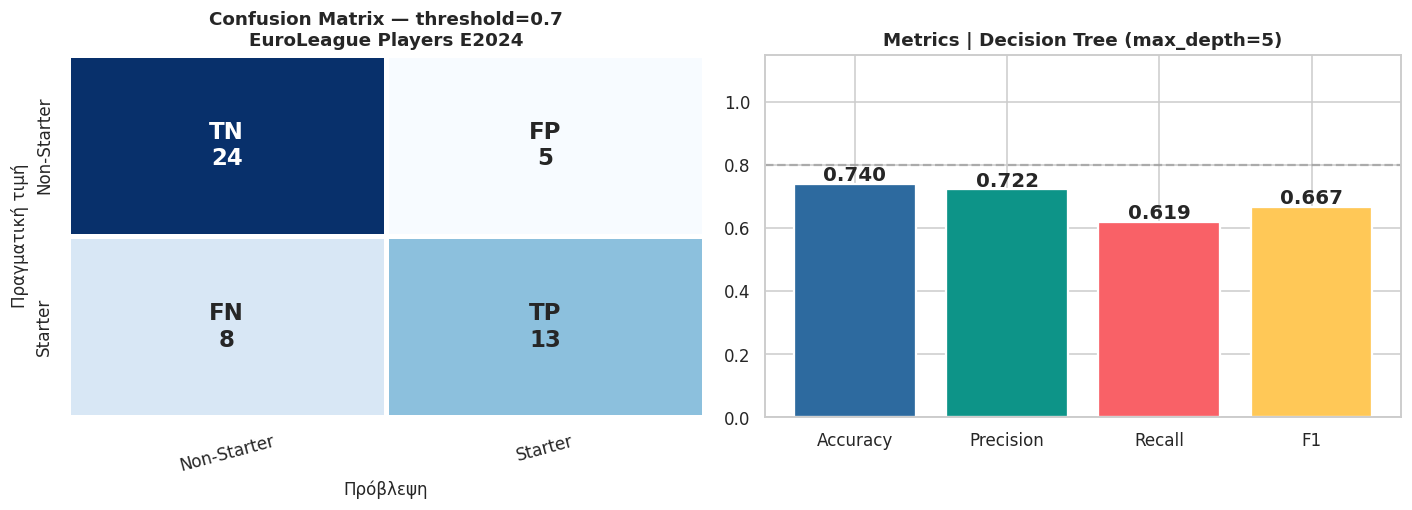


📊 TP=13  FP=5  FN=8  TN=24
   Accuracy=0.740 | Precision=0.722 | Recall=0.619 | F1=0.667

🔍 Ερμηνεία (EuroLeague Players E2024):
   FN=8 → Είπαμε 'non-starter' σε πραγματικό starter  [Scout: Χάσαμε ταλέντο που έπρεπε να προσληφθεί]
   FP=5 → Είπαμε 'starter' σε non-starter  [Roster Mgr: Λάθος παίκτης στο starting lineup]


In [109]:
cm = confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = cm.ravel()

acc  = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred, zero_division=0)
rec  = recall_score(y_test, y_pred, zero_division=0)
f1   = f1_score(y_test, y_pred, zero_division=0)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

# ── Confusion Matrix heatmap ──────────────────────────────────────────────────
ax = axes[0]
annot = np.array([[f"TN\n{tn}", f"FP\n{fp}"], [f"FN\n{fn}", f"TP\n{tp}"]])
sns.heatmap(cm, annot=annot, fmt="", cmap="Blues", ax=ax, linewidths=2, cbar=False,
            xticklabels=CTX["target_names"], yticklabels=CTX["target_names"],
            annot_kws={"size": 15, "weight": "bold"})
ax.set_xlabel("Πρόβλεψη", fontsize=11)
ax.set_ylabel("Πραγματική τιμή", fontsize=11)
ax.set_title(f"Confusion Matrix — threshold={THRESHOLD}\n{CTX['name']}", fontsize=12, fontweight="bold")
ax.tick_params(axis="x", rotation=15)

# ── Metrics bar chart ─────────────────────────────────────────────────────────
ax2 = axes[1]
metrics = {"Accuracy": acc, "Precision": prec, "Recall": rec, "F1": f1}
colors  = ["#2D6A9F", "#0D9488", "#F96167", "#FFC857"]
bars = ax2.bar(metrics.keys(), metrics.values(), color=colors, edgecolor="white", linewidth=1.5)
for bar, val in zip(bars, metrics.values()):
    ax2.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
             f"{val:.3f}", ha="center", fontsize=13, fontweight="bold")
ax2.set_ylim(0, 1.15)
ax2.set_title(f"Metrics | {model_label}", fontsize=12, fontweight="bold")
ax2.axhline(0.8, color="gray", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

print(f"\n📊 TP={tp}  FP={fp}  FN={fn}  TN={tn}")
print(f"   Accuracy={acc:.3f} | Precision={prec:.3f} | Recall={rec:.3f} | F1={f1:.3f}")
print()
print(f"🔍 Ερμηνεία ({CTX['name']}):")
print(f"   FN={fn} → {CTX['fn_meaning']}  [{CTX['fn_cost']}]")
print(f"   FP={fp} → {CTX['fp_meaning']}  [{CTX['fp_cost']}]")

---
## 4. Γιατί FP/FN σημαίνουν διαφορετικά πράγματα ανά domain

Αυτό είναι το **κεντρικό concept** του μαθήματος. Ο πίνακας παρακάτω το συνοψίζει:

| Dataset | Ρόλος | Τι κοστίζει περισσότερο | Σωστή στρατηγική |
|---------|-------|------------------------|------------------|
| **Breast Cancer** | Γιατρός | **FN** — χάσαμε καρκίνο | ↓ threshold → ↑ Recall |
| **EuroLeague** | Scout | **FN** — χάσαμε ταλέντο | ↓ threshold → ↑ Recall |
| **EuroLeague** | Roster Mgr | **FP** — λάθος παίκτης starter | ↑ threshold → ↑ Precision |
| **Spam filter** | Χρήστης | **FP** — σημαντικό email χάθηκε | ↑ threshold → ↑ Precision |

> **Το μοντέλο δεν αποφασίζει.** Αποφασίζεις **εσύ** — με το threshold — βάσει του business context.

### 📊 Τι θα δεις παρακάτω — Threshold Sweep

Το επόμενο cell τρέχει το μοντέλο για **κάθε δυνατό threshold** (0.05 → 0.95) και σχεδιάζει:

- **Αριστερά — Precision / Recall / F1 vs Threshold:**
  - Precision (πράσινο) ανεβαίνει καθώς ανεβαίνει το threshold
  - Recall (κόκκινο) κατεβαίνει — αυτό είναι το **trade-off**
  - F1 (κίτρινο διακεκομμένο) κορυφώνεται κάπου στη μέση
  - Η κάθετη μπλε γραμμή = το threshold που έχεις επιλέξει τώρα

- **Δεξιά — FP vs FN ανά threshold:**
  - Βλέπεις **πόσα λάθη κάθε τύπου** κάνει το μοντέλο
  - Καθώς ανεβαίνει το threshold: FP ↓, FN ↑
  - Το legend δείχνει τι κοστίζει το καθένα στο dataset σου

> 🔑 **Ερώτηση για σκέψη:** Πού θα έβαζες το threshold αν ήσουν γιατρός; Αν ήσουν Scout;


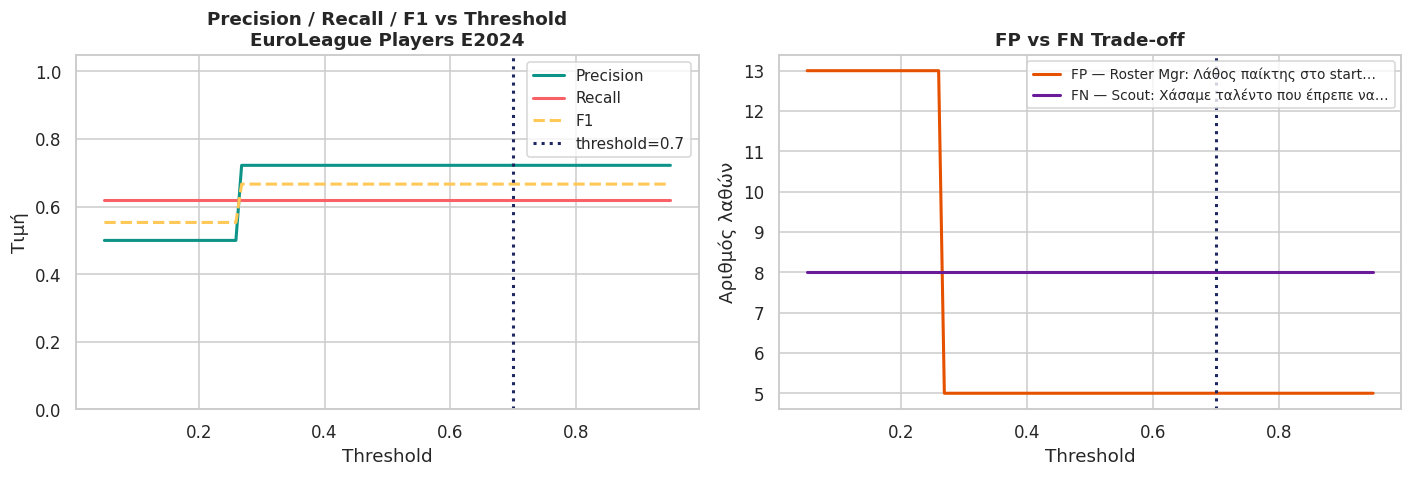


💡 Στρατηγική για EuroLeague Players E2024:
   Scout → thr=0.30 (↑ Recall) | Roster Mgr → thr=0.70 (↑ Precision)


In [110]:
# ── Threshold sweep: βλέπουμε πώς αλλάζουν τα metrics ───────────────────────
thresh_range = np.linspace(0.05, 0.95, 100)
rows = []
for t in thresh_range:
    yp = (y_proba >= t).astype(int)
    cm_t = confusion_matrix(y_test, yp, labels=[0,1]).ravel()
    tn_t, fp_t, fn_t, tp_t = cm_t
    rows.append({
        "t": t,
        "Precision": precision_score(y_test, yp, zero_division=0),
        "Recall":    recall_score(y_test, yp, zero_division=0),
        "F1":        f1_score(y_test, yp, zero_division=0),
        "FP": fp_t, "FN": fn_t,
    })
df_sw = pd.DataFrame(rows)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Αριστερά: Precision/Recall/F1
ax = axes[0]
ax.plot(df_sw["t"], df_sw["Precision"], color="#0D9488", lw=2, label="Precision")
ax.plot(df_sw["t"], df_sw["Recall"],    color="#F96167", lw=2, label="Recall")
ax.plot(df_sw["t"], df_sw["F1"],        color="#FFC857", lw=2, linestyle="--", label="F1")
ax.axvline(THRESHOLD, color="#1E2761", lw=2, linestyle=":", label=f"threshold={THRESHOLD}")
ax.set_xlabel("Threshold"); ax.set_ylabel("Τιμή")
ax.set_title(f"Precision / Recall / F1 vs Threshold\n{CTX['name']}", fontweight="bold")
ax.legend(fontsize=10); ax.set_ylim(0, 1.05)

# Δεξιά: FP/FN trade-off
ax2 = axes[1]
ax2.plot(df_sw["t"], df_sw["FP"], color="#E65100", lw=2, label=f"FP — {CTX['fp_cost'][:35]}…")
ax2.plot(df_sw["t"], df_sw["FN"], color="#6A1B9A", lw=2, label=f"FN — {CTX['fn_cost'][:35]}…")
ax2.axvline(THRESHOLD, color="#1E2761", lw=2, linestyle=":")
ax2.set_xlabel("Threshold"); ax2.set_ylabel("Αριθμός λαθών")
ax2.set_title("FP vs FN Trade-off", fontweight="bold")
ax2.legend(fontsize=9)

plt.tight_layout()
plt.show()

print(f"\n💡 Στρατηγική για {CTX['name']}:")
print(f"   {CTX['strategy']}")

---
## 5. ROC Curve & AUC

### 🔑 Τι είναι η ROC Curve;

Μέχρι τώρα είδαμε τι συμβαίνει για **ένα** threshold.  
Η ROC curve δείχνει τι συμβαίνει **για όλα** τα thresholds ταυτόχρονα.

Κάθε σημείο της καμπύλης = ένα διαφορετικό threshold:
- **Άξονας Y (TPR / Recall):** Πόσους θετικούς βρίσκουμε
- **Άξονας X (FPR):** Πόσους αρνητικούς λανθασμένα χαρακτηρίζουμε θετικούς

**AUC (Area Under Curve):** Ένας αριθμός που συνοψίζει ολόκληρη την καμπύλη:
| AUC | Σημαίνει |
|-----|---------|
| 1.0 | Τέλειο (στην πράξη: overfitting) |
| 0.9+ | Εξαιρετικό |
| 0.8–0.9 | Πολύ καλό |
| 0.7–0.8 | Καλό |
| 0.5 | Τυχαία εικασία (άχρηστο) |

### 📊 Τι θα δεις παρακάτω

- **Μπλε καμπύλη:** Το μοντέλό σου — όσο πιο «φουσκωτή» προς την πάνω αριστερά γωνία, τόσο καλύτερο
- **Γκρι διαγώνιος:** Τυχαία εικασία (AUC=0.5) — baseline σύγκρισης
- **Κόκκινο σημείο:** Το threshold που έχεις επιλέξει — **δείχνει πού βρίσκεσαι πάνω στην καμπύλη**
- **Σκιασμένη περιοχή:** Η AUC — η επιφάνεια κάτω από την καμπύλη

> 💡 **Σημαντικό:** Η AUC **δεν αλλάζει** όταν αλλάζεις threshold — μετράει την ποιότητα του μοντέλου αυτή καθεαυτή. Το threshold επιλέγει απλώς **ένα σημείο** πάνω στην ίδια καμπύλη.


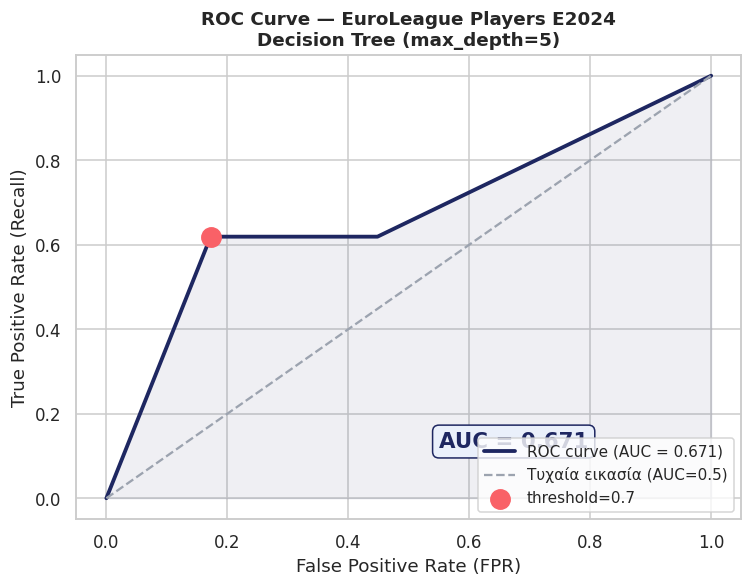


AUC = 0.671 → Μέτριο
Κόκκινο σημείο: threshold=0.7, FPR=0.17, TPR=0.62


In [111]:
fpr_arr, tpr_arr, roc_thr = roc_curve(y_test, y_proba)
auc = roc_auc_score(y_test, y_proba)
cur_idx = np.argmin(np.abs(roc_thr - THRESHOLD))

fig, ax = plt.subplots(figsize=(7, 5.5))
ax.plot(fpr_arr, tpr_arr, color="#1E2761", lw=2.5, label=f"ROC curve (AUC = {auc:.3f})")
ax.plot([0,1],[0,1], "--", color="#9CA3AF", lw=1.5, label="Τυχαία εικασία (AUC=0.5)")
ax.fill_between(fpr_arr, tpr_arr, alpha=0.07, color="#1E2761")
ax.scatter(fpr_arr[cur_idx], tpr_arr[cur_idx], s=160, color="#F96167", zorder=5,
           label=f"threshold={THRESHOLD}")
ax.set_xlabel("False Positive Rate (FPR)", fontsize=12)
ax.set_ylabel("True Positive Rate (Recall)", fontsize=12)
ax.set_title(f"ROC Curve — {CTX['name']}\n{model_label}", fontsize=12, fontweight="bold")
ax.legend(fontsize=10, loc="lower right")
ax.text(0.55, 0.12, f"AUC = {auc:.3f}", fontsize=14, fontweight="bold",
        color="#1E2761", bbox=dict(boxstyle="round", facecolor="#EAF0FB", edgecolor="#1E2761"))
plt.tight_layout()
plt.show()

rating = "Άριστο" if auc > 0.95 else "Πολύ καλό" if auc > 0.85 else "Καλό" if auc > 0.75 else "Μέτριο"
print(f"\nAUC = {auc:.3f} → {rating}")
print(f"Κόκκινο σημείο: threshold={THRESHOLD}, FPR={fpr_arr[cur_idx]:.2f}, TPR={tpr_arr[cur_idx]:.2f}")

---
## 6. Σύγκριση: Breast Cancer vs EuroLeague

### 🔑 Γιατί αυτή η σύγκριση;

Ώς εδώ δουλέψαμε με **ένα** dataset τη φορά. Τώρα βλέπουμε και τα δύο **παράλληλα**,  
με thresholds που αντικατοπτρίζουν τον **ρόλο** του χρήστη:

| Σενάριο | Dataset | Threshold | Λογική |
|---------|---------|-----------|--------|
| 🏥 Γιατρός | breast_cancer | 0.30 | Πιάσε ΟΛΟΥΣ τους αρρώστους |
| 🔍 Scout | euroleague | 0.30 | Πιάσε ΟΛΟΥΣ τους starters |
| 📋 Roster Mgr | euroleague | 0.70 | Μόνο ΣΙΓΟΥΡΟΥΣ starters |

### 📊 Τι θα δεις παρακάτω

- **Αριστερά — ROC Curves σε ένα γράφημα:**
  - Κάθε χρώμα = ένα σενάριο
  - Βλέπεις ποιο dataset είναι «ευκολότερο» για το μοντέλο (υψηλότερη AUC)
  - Θυμήσου: η AUC δεν αλλάζει με το threshold — οι 2 EuroLeague γραμμές είναι **ίδιες**!

- **Δεξιά — Grouped bars Precision / Recall / F1:**
  - Εδώ φαίνεται καθαρά το threshold trade-off
  - Scout (thr=0.30): **υψηλό Recall**, χαμηλότερο Precision
  - Roster Mgr (thr=0.70): **υψηλή Precision**, χαμηλότερο Recall

> 🔑 **Κεντρική παρατήρηση:** Ίδιο μοντέλο + ίδια δεδομένα + **διαφορετικό threshold** = πολύ διαφορετικά αποτελέσματα. Το «καλύτερο» threshold εξαρτάται από το business context, όχι από τα μαθηματικά.


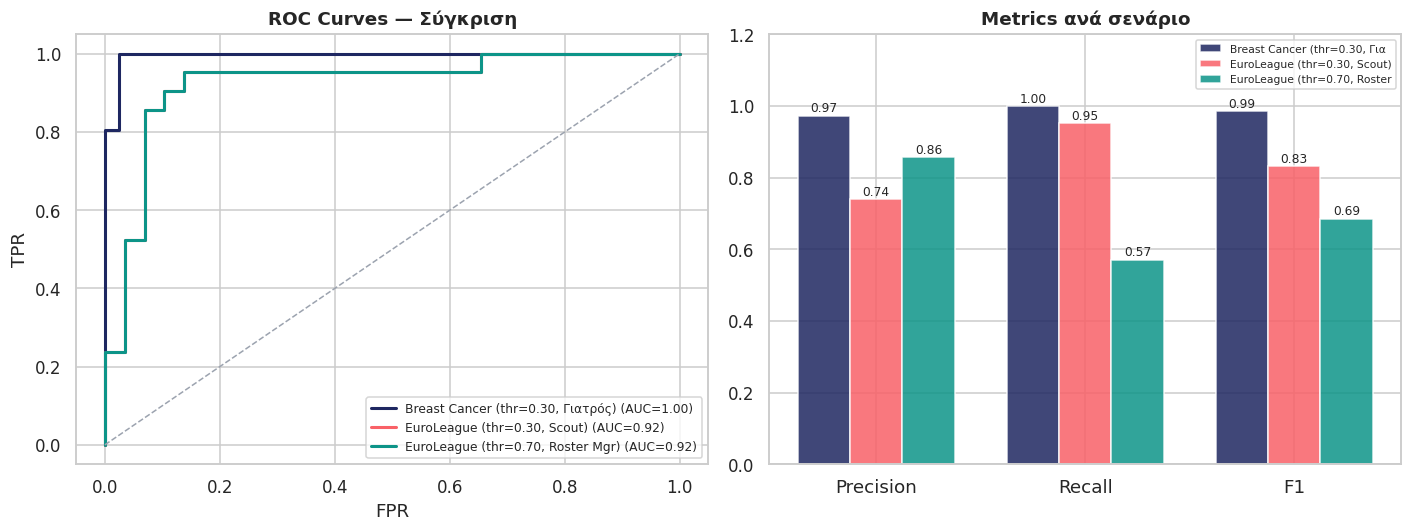


📋 Σύνοψη:
                          Σενάριο  Threshold   AUC  Precision  Recall    F1 Class %
Breast Cancer (thr=0.30, Γιατρός)      0.300 0.995      0.973   1.000 0.986     63%
     EuroLeague (thr=0.30, Scout)      0.300 0.924      0.741   0.952 0.833     41%
EuroLeague (thr=0.70, Roster Mgr)      0.700 0.924      0.857   0.571 0.686     41%

💡 Παρατήρησε:
   • Το AUC δεν αλλάζει με το threshold — μετράει το μοντέλο αυτό καθεαυτό
   • Precision και Recall κινούνται αντίθετα όταν αλλάζει το threshold
   • Το ίδιο threshold (0.30) δίνει διαφορετικό αποτέλεσμα σε διαφορετικά datasets


In [112]:
scenarios = [
    {"label": "Breast Cancer\n(thr=0.30, Γιατρός)",   "loader": load_breast_cancer_data, "thr": 0.30},
    {"label": "EuroLeague\n(thr=0.30, Scout)",         "loader": load_euroleague_data,    "thr": 0.30},
    {"label": "EuroLeague\n(thr=0.70, Roster Mgr)",    "loader": load_euroleague_data,    "thr": 0.70},
]

results_cmp = []
roc_data    = []
colors_cmp  = ["#1E2761", "#F96167", "#0D9488"]

for sc in scenarios:
    try:
        Xd, yd, ctxd = sc["loader"]()
        Xtr, Xte, ytr, yte = train_test_split(Xd, yd, test_size=0.2, random_state=42, stratify=yd)
        p = Pipeline([("s", StandardScaler()), ("m", LogisticRegression(max_iter=1000, random_state=42))])
        p.fit(Xtr, ytr)
        prob = p.predict_proba(Xte)[:, 1]
        yp   = (prob >= sc["thr"]).astype(int)
        results_cmp.append({
            "Σενάριο":   sc["label"].replace("\n"," "),
            "Threshold": sc["thr"],
            "AUC":       roc_auc_score(yte, prob),
            "Precision": precision_score(yte, yp, zero_division=0),
            "Recall":    recall_score(yte, yp, zero_division=0),
            "F1":        f1_score(yte, yp, zero_division=0),
            "Class %":   f"{yd.mean()*100:.0f}%",
        })
        fpr_c, tpr_c, _ = roc_curve(yte, prob)
        roc_data.append({"label": sc["label"], "fpr": fpr_c, "tpr": tpr_c,
                         "auc": roc_auc_score(yte, prob)})
    except Exception as e:
        print(f"⚠️  '{sc['label'].split(chr(10))[0]}' δεν φορτώθηκε: {e}")

if not results_cmp:
    print("Δεν φορτώθηκε κανένα dataset για σύγκριση.")
else:
    df_cmp = pd.DataFrame(results_cmp)

    fig, axes = plt.subplots(1, 2, figsize=(13, 5))

    # ROC curves
    ax = axes[0]
    for rd, col in zip(roc_data, colors_cmp):
        ax.plot(rd["fpr"], rd["tpr"], lw=2, color=col,
                label=f"{rd['label'].replace(chr(10),' ')} (AUC={rd['auc']:.2f})")
    ax.plot([0,1],[0,1],"--",color="#9CA3AF",lw=1)
    ax.set_xlabel("FPR"); ax.set_ylabel("TPR")
    ax.set_title("ROC Curves — Σύγκριση", fontweight="bold")
    ax.legend(fontsize=8, loc="lower right")

    # Grouped bar — Precision / Recall / F1
    ax2 = axes[1]
    mnames = ["Precision", "Recall", "F1"]
    x = np.arange(len(mnames))
    w = 0.25
    for i, (row, col) in enumerate(zip(results_cmp, colors_cmp)):
        vals = [row["Precision"], row["Recall"], row["F1"]]
        bs   = ax2.bar(x + i*w, vals, w, label=row["Σενάριο"][:28], color=col, alpha=0.85)
        for b, v in zip(bs, vals):
            ax2.text(b.get_x()+b.get_width()/2, b.get_height()+0.01, f"{v:.2f}",
                     ha="center", fontsize=8)
    ax2.set_xticks(x + w)
    ax2.set_xticklabels(mnames, fontsize=12)
    ax2.set_ylim(0, 1.2)
    ax2.set_title("Metrics ανά σενάριο", fontweight="bold")
    ax2.legend(fontsize=7)

    plt.tight_layout()
    plt.show()

    print("\n📋 Σύνοψη:")
    print(df_cmp.to_string(index=False, float_format="{:.3f}".format))
    print()
    print("💡 Παρατήρησε:")
    print("   • Το AUC δεν αλλάζει με το threshold — μετράει το μοντέλο αυτό καθεαυτό")
    print("   • Precision και Recall κινούνται αντίθετα όταν αλλάζει το threshold")
    print("   • Το ίδιο threshold (0.30) δίνει διαφορετικό αποτέλεσμα σε διαφορετικά datasets")

---
## 7. Class Imbalance — Ανισόρροπα Δεδομένα

### 🔑 Το πρόβλημα

Όταν μια κλάση έχει **πολύ λιγότερα δείγματα**, το μοντέλο μαθαίνει να αγνοεί τη μειονότητα.

> Παράδειγμα: 95% αρνητικά → μοντέλο που λέει πάντα "αρνητικό" = 95% accuracy, 0% Recall.

### Λύση: `class_weight='balanced'`

Λέει στον αλγόριθμο να **ζυγίζει περισσότερο** τα λάθη στη μειονότητα.
Αλλαγή: 1 παράμετρος!

```python
LogisticRegression(class_weight='balanced')
```

### 📊 Τι θα δεις παρακάτω
- **Αριστερά:** Κατανομή κλάσεων (bar chart) — πόσο ανισόρροπο είναι το dataset
- **Δεξιά:** Σύγκριση metrics **με** και **χωρίς** class_weight

> 💡 Άλλαξε `USE_CLASS_WEIGHT = True` στα knobs και τρέξε ξανά — κοίτα τι αλλάζει στο Recall!


📊 Κατανομή κλάσεων — EuroLeague Players E2024
   Θετική (1):  102  (41.3%)
   Αρνητική (0):  145  (58.7%)
   Αναλογία: 1 : 1.4
   ✅ Σχετικά ισόρροπο dataset.


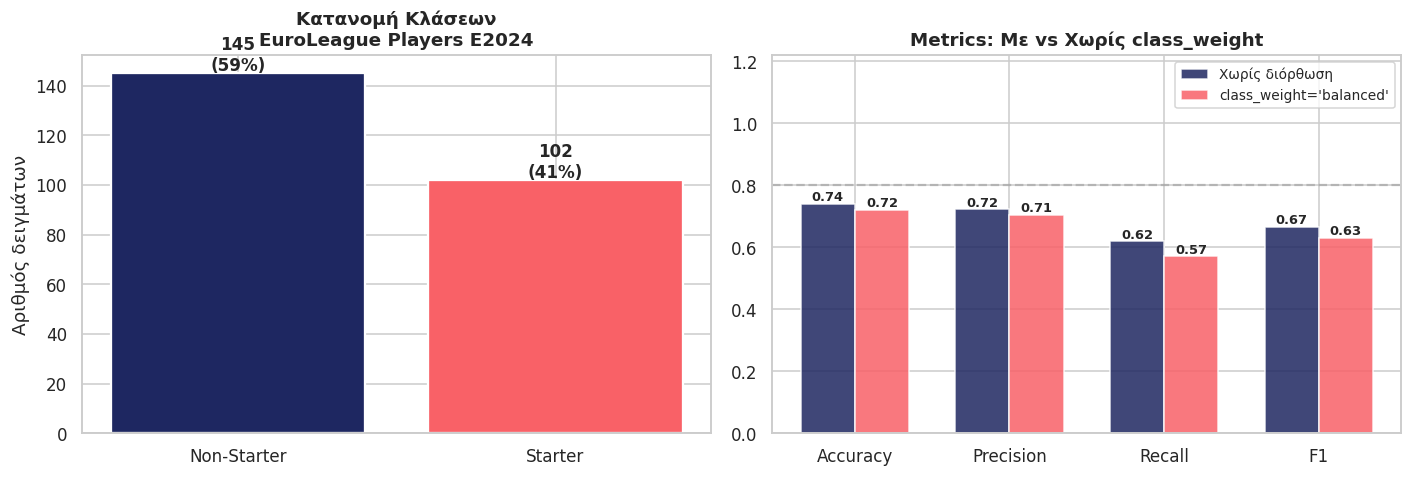


🔧 Τρέχον knob: USE_CLASS_WEIGHT = True  →  class_weight='balanced'
   Recall με διόρθωση:    0.571
   Recall χωρίς διόρθωση: 0.619

💡 Παρατήρησε: το class_weight βελτιώνει το Recall αλλά μπορεί να μειώσει Precision.


In [113]:
# ── Class balance visualization ───────────────────────────────────────────
class_counts = pd.Series(y).value_counts().sort_index()
pos_count = int((y == 1).sum())
neg_count = int((y == 0).sum())
total = len(y)
imbalance_ratio = neg_count / pos_count if pos_count > 0 else float('inf')

print(f"📊 Κατανομή κλάσεων — {CTX['name']}")
print(f"   Θετική (1): {pos_count:4d}  ({pos_count/total*100:.1f}%)")
print(f"   Αρνητική (0): {neg_count:4d}  ({neg_count/total*100:.1f}%)")
print(f"   Αναλογία: 1 : {imbalance_ratio:.1f}")
if imbalance_ratio > 5:
    print(f"   ⚠️  Σοβαρή ανισορροπία! class_weight='balanced' συνιστάται.")
elif imbalance_ratio > 2:
    print(f"   ⚠️  Μέτρια ανισορροπία.")
else:
    print(f"   ✅ Σχετικά ισόρροπο dataset.")

# ── Train two models: with/without class_weight ────────────────────────────
cw = "balanced" if USE_CLASS_WEIGHT else None

if MODEL_NAME == "logreg":
    clf_no  = LogisticRegression(random_state=RANDOM_STATE, max_iter=1000, class_weight=None)
    clf_cw  = LogisticRegression(random_state=RANDOM_STATE, max_iter=1000, class_weight="balanced")
else:
    clf_no  = DecisionTreeClassifier(max_depth=5, random_state=RANDOM_STATE, class_weight=None)
    clf_cw  = DecisionTreeClassifier(max_depth=5, random_state=RANDOM_STATE, class_weight="balanced")

results_imb = {}
for label, clf_i in [("Χωρίς διόρθωση", clf_no), ("class_weight='balanced'", clf_cw)]:
    p_i = Pipeline([("s", StandardScaler()), ("m", clf_i)])
    p_i.fit(X_train, y_train)
    prob_i = p_i.predict_proba(X_test)[:, 1]
    yp_i   = (prob_i >= THRESHOLD).astype(int)
    results_imb[label] = {
        "Accuracy":  accuracy_score(y_test, yp_i),
        "Precision": precision_score(y_test, yp_i, zero_division=0),
        "Recall":    recall_score(y_test, yp_i, zero_division=0),
        "F1":        f1_score(y_test, yp_i, zero_division=0),
    }

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Class distribution
ax = axes[0]
bars = ax.bar(CTX["target_names"], class_counts.values,
              color=[C_PLOT["accent"] if i == 1 else C_PLOT["navy"] for i in range(len(class_counts))],
              edgecolor="white", linewidth=1.5)
for bar, val in zip(bars, class_counts.values):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1,
            f"{val}\n({val/total*100:.0f}%)", ha="center", fontsize=11, fontweight="bold")
ax.set_title(f"Κατανομή Κλάσεων\n{CTX['name']}", fontweight="bold")
ax.set_ylabel("Αριθμός δειγμάτων")

# Metrics comparison
ax2 = axes[1]
metric_names = ["Accuracy", "Precision", "Recall", "F1"]
x = np.arange(len(metric_names))
w = 0.35
colors_pair = [C_PLOT["navy"], C_PLOT["accent"]]
for j, (label, res) in enumerate(results_imb.items()):
    vals = [res[m] for m in metric_names]
    bs = ax2.bar(x + j*w - w/2, vals, w, label=label, color=colors_pair[j], alpha=0.85, edgecolor="white")
    for b, v in zip(bs, vals):
        ax2.text(b.get_x()+b.get_width()/2, b.get_height()+0.01, f"{v:.2f}",
                 ha="center", fontsize=8.5, fontweight="bold")
ax2.set_xticks(x)
ax2.set_xticklabels(metric_names, fontsize=11)
ax2.set_ylim(0, 1.22)
ax2.set_title("Metrics: Με vs Χωρίς class_weight", fontweight="bold")
ax2.legend(fontsize=9)
ax2.axhline(0.8, color="gray", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

active = "class_weight='balanced'" if USE_CLASS_WEIGHT else "Χωρίς διόρθωση"
print(f"\n🔧 Τρέχον knob: USE_CLASS_WEIGHT = {USE_CLASS_WEIGHT}  →  {active}")
cw_key = "class_weight='balanced'"
print(f"   Recall με διόρθωση:    {results_imb[cw_key]['Recall']:.3f}")
print(f"   Recall χωρίς διόρθωση: {results_imb['Χωρίς διόρθωση']['Recall']:.3f}")
print(f"\n💡 Παρατήρησε: το class_weight βελτιώνει το Recall αλλά μπορεί να μειώσει Precision.")


---
## 8. Cross-Validation — Αξιόπιστη Αξιολόγηση

### 🔑 Γιατί ένα split δεν αρκεί

Ένα μόνο train/test split μπορεί να δώσει τυχαία καλό ή κακό αποτέλεσμα — εξαρτάται από το πώς τυχαία χωρίστηκαν τα δεδομένα.

Η **K-Fold Cross-Validation** λύνει αυτό:
1. Χωρίζει τα δεδομένα σε **K ίσα τμήματα (folds)**
2. Επαναλαμβάνει K φορές — κάθε φορά άλλο fold γίνεται test
3. Αποτέλεσμα: **mean AUC ± std** — πολύ πιο αξιόπιστο

### 📊 Τι θα δεις παρακάτω
- **Αριστερά:** AUC για κάθε fold ξεχωριστά (dot plot) — βλέπεις τη διακύμανση
- **Δεξιά:** Σύγκριση: single split AUC vs CV mean AUC

> 💡 Άλλαξε `N_CV_FOLDS` από 3 → 5 → 10 και κοίτα πώς αλλάζει το ± std!


📊 Cross-Validation (10-Fold) — EuroLeague Players E2024
   AUC ανά fold: ['0.834', '0.815', '0.747', '0.780', '0.797', '0.850', '0.740', '0.739', '0.882', '0.721']
   Mean AUC: 0.791  (± 0.051)
   Single split AUC: 0.671
   ✅ Χαμηλή διακύμανση — αξιόπιστο μοντέλο.


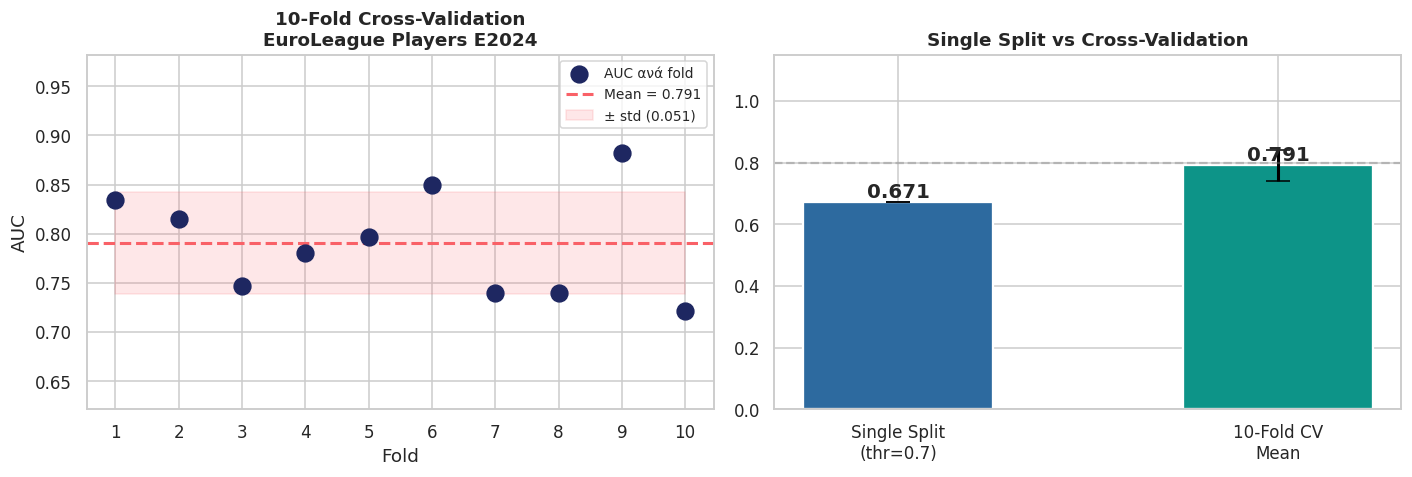

In [114]:
from sklearn.model_selection import cross_val_score

# ── Cross-Validation ───────────────────────────────────────────────────────
cw = "balanced" if USE_CLASS_WEIGHT else None
if MODEL_NAME == "logreg":
    clf_cv = LogisticRegression(random_state=RANDOM_STATE, max_iter=1000, class_weight=cw)
else:
    clf_cv = DecisionTreeClassifier(max_depth=5, random_state=RANDOM_STATE, class_weight=cw)

pipe_cv = Pipeline([("s", StandardScaler()), ("m", clf_cv)])

cv_scores = cross_val_score(pipe_cv, X, y, cv=N_CV_FOLDS, scoring="roc_auc")
single_auc = roc_auc_score(y_test, y_proba)

print(f"📊 Cross-Validation ({N_CV_FOLDS}-Fold) — {CTX['name']}")
print(f"   AUC ανά fold: {[f'{s:.3f}' for s in cv_scores]}")
print(f"   Mean AUC: {cv_scores.mean():.3f}  (± {cv_scores.std():.3f})")
print(f"   Single split AUC: {single_auc:.3f}")

if cv_scores.std() > 0.1:
    print(f"   ⚠️  Μεγάλη διακύμανση ({cv_scores.std():.3f}) — το μοντέλο δεν είναι σταθερό!")
else:
    print(f"   ✅ Χαμηλή διακύμανση — αξιόπιστο μοντέλο.")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Left: per-fold AUC
ax = axes[0]
fold_nums = np.arange(1, N_CV_FOLDS + 1)
ax.scatter(fold_nums, cv_scores, s=120, color=C_PLOT["navy"], zorder=5, label="AUC ανά fold")
ax.axhline(cv_scores.mean(), color=C_PLOT["accent"], lw=2, linestyle="--",
           label=f"Mean = {cv_scores.mean():.3f}")
ax.fill_between(fold_nums,
                cv_scores.mean() - cv_scores.std(),
                cv_scores.mean() + cv_scores.std(),
                alpha=0.15, color=C_PLOT["accent"], label=f"± std ({cv_scores.std():.3f})")
ax.set_xlabel("Fold")
ax.set_ylabel("AUC")
ax.set_xticks(fold_nums)
ax.set_ylim(max(0, cv_scores.min() - 0.1), min(1.05, cv_scores.max() + 0.1))
ax.set_title(f"{N_CV_FOLDS}-Fold Cross-Validation\n{CTX['name']}", fontweight="bold")
ax.legend(fontsize=9)

# Right: single vs CV comparison
ax2 = axes[1]
labels_cmp = [f"Single Split\n(thr={THRESHOLD})", f"{N_CV_FOLDS}-Fold CV\nMean"]
vals_cmp   = [single_auc, cv_scores.mean()]
errs_cmp   = [0, cv_scores.std()]
bars = ax2.bar(labels_cmp, vals_cmp, color=[C_PLOT["blue"], C_PLOT["teal"]],
               edgecolor="white", linewidth=1.5, width=0.5)
ax2.errorbar([0, 1], vals_cmp, yerr=errs_cmp, fmt="none", color="black", capsize=8, linewidth=2)
for bar, val in zip(bars, vals_cmp):
    ax2.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.015,
             f"{val:.3f}", ha="center", fontsize=13, fontweight="bold")
ax2.set_ylim(0, 1.15)
ax2.set_title("Single Split vs Cross-Validation", fontweight="bold")
ax2.axhline(0.8, color="gray", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()


---
## 9. Learning Curves — Διάγνωση Overfitting & Underfitting

### 🔑 Τι είναι

Οι learning curves δείχνουν πώς αλλάζει η απόδοση καθώς αυξάνουμε τα **δεδομένα εκπαίδευσης**.

| Πρόβλημα | Train score | Validation score | Λύση |
|----------|-------------|------------------|------|
| **Καλό μοντέλο** | Ψηλό | Ψηλό & κοντά στο train | — |
| **Overfitting** | Πολύ ψηλό | Χαμηλό (μεγάλο χάσμα) | Regularization, max_depth↓ |
| **Underfitting** | Χαμηλό | Χαμηλό | Πιο σύνθετο μοντέλο |

### 📊 Τι θα δεις παρακάτω
- **Μπλε γραμμή (Train):** Το score στα training data — συνήθως αρχίζει ψηλά
- **Πράσινη γραμμή (Validation):** Το score σε unseen data — η πραγματική απόδοση
- **Χάσμα μεταξύ τους** = overfitting

> 💡 Δοκίμασε `MODEL_NAME="tree"` — το Decision Tree χωρίς περιορισμό overfits πολύ!


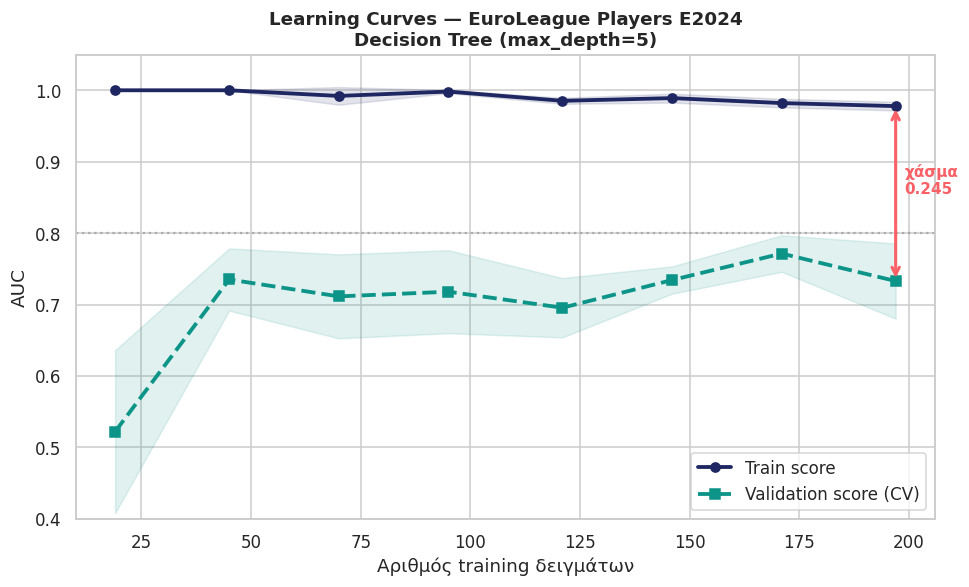


📊 Τελικά scores (με όλα τα train data):
   Train AUC:      0.978 (± 0.006)
   Validation AUC: 0.733 (± 0.053)
   Χάσμα:          0.245
   ⚠️  Overfitting! Μεγάλο χάσμα — το μοντέλο απομνημόνευσε.
   💡 Δοκίμασε: μικρότερο max_depth, ή περισσότερα δεδομένα.


In [115]:
from sklearn.model_selection import learning_curve

# ── Learning Curves ────────────────────────────────────────────────────────
cw = "balanced" if USE_CLASS_WEIGHT else None
if MODEL_NAME == "logreg":
    clf_lc = LogisticRegression(random_state=RANDOM_STATE, max_iter=1000, class_weight=cw)
    model_label_lc = "Logistic Regression"
else:
    clf_lc = DecisionTreeClassifier(max_depth=5, random_state=RANDOM_STATE, class_weight=cw)
    model_label_lc = "Decision Tree (max_depth=5)"

pipe_lc = Pipeline([("s", StandardScaler()), ("m", clf_lc)])

train_sizes, train_scores, val_scores = learning_curve(
    pipe_lc, X, y,
    cv=5, scoring="roc_auc",
    train_sizes=np.linspace(0.1, 1.0, 8),
    n_jobs=-1
)

train_mean = train_scores.mean(axis=1)
train_std  = train_scores.std(axis=1)
val_mean   = val_scores.mean(axis=1)
val_std    = val_scores.std(axis=1)

gap = train_mean[-1] - val_mean[-1]

fig, ax = plt.subplots(figsize=(9, 5.5))
ax.plot(train_sizes, train_mean, "o-", color=C_PLOT["navy"], lw=2.5, label="Train score")
ax.fill_between(train_sizes, train_mean-train_std, train_mean+train_std,
                alpha=0.12, color=C_PLOT["navy"])
ax.plot(train_sizes, val_mean, "s--", color=C_PLOT["teal"], lw=2.5, label="Validation score (CV)")
ax.fill_between(train_sizes, val_mean-val_std, val_mean+val_std,
                alpha=0.12, color=C_PLOT["teal"])

# Annotate gap
ax.annotate("", xy=(train_sizes[-1], val_mean[-1]),
            xytext=(train_sizes[-1], train_mean[-1]),
            arrowprops=dict(arrowstyle="<->", color=C_PLOT["accent"], lw=2))
ax.text(train_sizes[-1]*1.01, (train_mean[-1]+val_mean[-1])/2,
        f"χάσμα\n{gap:.3f}", color=C_PLOT["accent"], fontsize=10, fontweight="bold")

ax.set_xlabel("Αριθμός training δειγμάτων", fontsize=12)
ax.set_ylabel("AUC", fontsize=12)
ax.set_title(f"Learning Curves — {CTX['name']}\n{model_label_lc}", fontsize=12, fontweight="bold")
ax.legend(fontsize=11)
ax.set_ylim(0.4, 1.05)
ax.axhline(0.8, color="gray", linestyle=":", alpha=0.5)
plt.tight_layout()
plt.show()

print(f"\n📊 Τελικά scores (με όλα τα train data):")
print(f"   Train AUC:      {train_mean[-1]:.3f} (± {train_std[-1]:.3f})")
print(f"   Validation AUC: {val_mean[-1]:.3f} (± {val_std[-1]:.3f})")
print(f"   Χάσμα:          {gap:.3f}")

if gap > 0.15:
    print(f"   ⚠️  Overfitting! Μεγάλο χάσμα — το μοντέλο απομνημόνευσε.")
    print(f"   💡 Δοκίμασε: μικρότερο max_depth, ή περισσότερα δεδομένα.")
elif val_mean[-1] < 0.7:
    print(f"   ⚠️  Underfitting — και τα δύο scores χαμηλά.")
    print(f"   💡 Δοκίμασε: πιο σύνθετο μοντέλο.")
else:
    print(f"   ✅ Καλή μάθηση — train και validation σύγκλινουν.")


---
## ✅ Ερωτήσεις Αξιολόγησης

Απάντα στις παρακάτω ερωτήσεις προσθέτοντας **νέα markdown cells** μετά από κάθε ερώτηση.

---

**1. Confusion Matrix & Metrics — Ιατρική:**
Με `DATASET="breast_cancer"` και `THRESHOLD=0.50`, πόσα FN έχει το μοντέλο;
Τι σημαίνει αυτό για έναν ασθενή; Γιατί είναι πιο σοβαρό από τα FP;



Το μοντέλο έχει 1 FN και 1 FP. Στην περίπτωση του FN (False Negative), το μοντέλο προέβλεψε λάθος ότι ένας όγκος είναι καλοήθης, ενώ στην πραγματικότητα ήταν κακοήθης. Αυτό σημαίνει ότι ο ασθενής δεν θα λάβει την κατάλληλη αγωγή ή δεν θα προγραμματιστεί εγκαίρως το αναγκαίο χειρουργείο. Η απώλεια αυτού του πολύτιμου χρόνου (golden time) μπορεί να στερήσει την ευκαιρία για πλήρη θεραπεία ή, στη χειρότερη περίπτωση, την επιμήκυνση της επιβίωσης και τη βελτίωση της ποιότητας ζωής του, οδηγώντας στο τέλος σε απώλεια ζωής.
Αντίθετα, στην περίπτωση του FP (False Positive), το μοντέλο διέγνωσε ως κακοήθη έναν όγκο που ήταν καλοήθης. Αυτό έχει ως αποτέλεσμα την  ψυχολογική καταπόνηση του ασθενή και πολύ πιθανόν την παραμονή του στο νοσοκομείο για περαιτέρω  ιατρικές εξετάσεις κλπ, χωρίς όμως να έχει άμεσο κίνδυνο τη ζωή του.

---

**2. Threshold & Ρόλοι:**
Με `DATASET="euroleague"`, δοκίμασε `THRESHOLD=0.30` και `THRESHOLD=0.70`.
Ποιο threshold θα επέλεγες αν ήσουν **Scout** και ποιο αν ήσουν **Roster Manager**; Γιατί;
Ποια μετρική (Precision ή Recall) μεγιστοποιείς σε κάθε περίπτωση;



Αν ήμουν Scout, θα επέλεγα το χαμηλό threshold (0.30) με σκοπό να μεγιστοποιήσω τo Recall. Ο λόγος είναι ότι, για τον συγκεκριμένο ρόλο, το μεγαλύτερο ρίσκο είναι το False Negative, δηλαδή να μην αναγνωρίσω ένα τεράστιο ταλέντο. Κατεβάζοντας τον πήχη (κοιτώντας σε πιο μικρές ομάδες), το μοντέλο γίνεται πιο επιεικές, διασφαλίζοντας έτσι ότι θα εντοπίσω όλους τους καλούς παίκτες παρόλα αυτά υπάρχει μεγάλη πιθανότητα ναχάσω τόν χρόνο μου  παίκτες που τελικά δεν θα αποδείξουν την αξία τους (αύξηση των False Positives). Αυτό βέβαια είναι αναγκαίο προκειμένου να είμαι απόλυτα σίγουρος ότι δεν θα χάσω το επόμενο μεγάλο ταλέντο άρα και θα κρατήσω την δουλειά μου. Τώρα αν ήμουν Roster manager θα επέλεγα υψηλό threshold (0.70) με σκοπό να μεγιστοποιείσω το precision. Σε κάθε αγώνα μπορούν να πάιξουν 12 παίχτες. Αυξάνοντας το threshold κάνουμε το μοντέλο πολύ πιο αυστηρό μπορεί δηλαδή να χάσουμε καποιον καλό παίχτη(FN) αλλά κρατάμε το (FP) χαμήλα με την έννοια οτι όσοι επιλεχθουν στην 12καδα το αξίζουν πραγματικά και η νίκη της ομάδας είναι πιο πιθανή.

---

**3. Class Imbalance:**
Κοίτα το class balance που εκτυπώνεται στο Section 7 για το dataset σου.
Τι αλλάζει στο **Recall** όταν βάζεις `USE_CLASS_WEIGHT=True`;
Τι "πληρώνεις" σε αντάλλαγμα (κοίτα Precision); Αξίζει η ανταλλαγή; Εξήγησε.



3α. Στην περίπτωση του breast cancer όταν βάζουμε true παρατηρούμε ότι το recall από το 0,986 πέφτει στο 0,944 και το precision παρέμεινε σταθερό. Αυτό σημαίνει πως δεν αποκτήσαμε ακρίβεια αλλά αντιθέτως μείωσαμε την ικανότητα εντοπισμού διότι είναι είδη απο την αρχή balanced τα δεδομένα οπότε όταν κάνουμε την αλλαγή εμείς εκείνο δίνει βάσει στην μειονότητα και να κάνει χαρακτηρίζει τους καλοήθεις ως καλοήθεις πιο δύσκολα. Επίσης δεν χρειάζεται να αλλαξουμε το true με το false γιατί ο κώδικας μας δείχνει και τα δύο ταυτόχρονα.

3β. Στην περίπτωση της euroleague βλέπουμε οτι αν κάνουμε balance το recall και precision αυξάνονται ενώ κανονικά θα έπρεπε να βλέπαμε αύξηση του recall και μείωση του precision αυτό συμβαίνει επειδή τα δεδομενα ηταν αρκετα καλα κατανενημένα από την αρχή οπότε με την αλλαγη που κάναμε βοηθήσαμς το μοντέλο να πάρει πιο σίγουρα τις αποφάσεις του σε αντίθεση με το breast cancer που παρόλο που τα δεδεμένα ήταν κατανεμημένα δεν ήταν τόσο σωστά με αποτέλεσμα να δωσεί εμφαση στηνμειωνότητα.

---

**4. Cross-Validation:**
Τρέξε με `N_CV_FOLDS=3`, μετά με `N_CV_FOLDS=10`.
Πώς αλλάζει το ± std; Τι σου λέει μεγάλο std για ένα μοντέλο;
Αν το CV AUC είναι 0.91 ± 0.02, είναι αξιόπιστο; Και αν είναι 0.91 ± 0.18;



4α. Στην περίπτωση του Breast Cancer, όπως και γενικά, το std (τυπική απόκλιση) μας δείχνει πόσο σταθερό είναι το μοντέλο μας κατά το Cross-Validation, αφού πρώτα έχουμε χωρίσει τα δεδομένα μας σε ομάδες (folds).Πηγαίνοντας από τα 3 στα 10 folds, παρατηρούμε ότι το std αυξάνεται ελάχιστα (από ±0.003 σε ±0.005). Παρόλα αυτά, η αύξηση και η τελική απόκλιση είναι πολύ μικρές, οπότε το μοντέλο μας θεωρείται εξαιρετικά αξιόπιστο και, κατ' επέκταση, τα δεδομένα μας είναι ποιοτικά. Σε ένα μοντέλο, το μεγάλο std δεν σημαίνει απαραίτητα ότι ο αλγόριθμος χρειάζεται βελτίωση. Συχνά υποδεικνύει ότι τα δεδομένα που χρησιμοποιεί έχουν προβλήματα ( δεν είναι "καθαρά", δεν υπάρχει επαρκής όγκος δεδομένων, ή δεν υπάρχει σωστή κατανομή/αντιπροσωπευτικότητα στα folds που "σπάνε"). Βάσει αυτών, ένα μοντέλο με CV AUC 0.91 ± 0.02 θεωρείται αξιόπιστο, καθώς η απόκλιση είναι μόλις 2%. Αντίθετα, αν το μοντέλο έχει απόκλιση ± 0.18 (18%), αυτό σημαίνει ότι είναι ιδιαίτερα ασταθές και η απόδοσή του εξαρτάται σε μεγάλο βαθμό από την 'τύχη' και δεν μπορούμε να το εμπιστευτούμε.

4β.Σε αντίθεση με τα δεδομένα του Breast Cancer, η αύξηση των folds από 3 σε 10 εκτοξεύει κατα πολύ το std από ±0.018 σε ±0.084 (8.4%). Όπως εξηγήθηκε στο 4α, αυτό υποδεικνύει πρόβλημα στα δεδομένα και όχι αλγορίθμου. Όταν ένα ήδη μικρό dataset σπάει σε 10 μικρότερα, χάνεται η αξιοπιστία δηλαδή αρκούν μερικά "θολά" δεδομένα σε ένα fold για να αποτύχει το μοντέλο. Επομένως αυτή η μεγάλη απόκλιση αποδεικνύει ότι το μοντέλο είναι ασταθές. Η ικανότητα γενίκευσής του εξαρτάται υπερβολικά από την «τύχη» του διαχωρισμού των δεδομένων και το καθιστά λιγότερο αξιόπιστο.

---

**5. Learning Curves — Overfitting/Underfitting:**
Τρέξε με `MODEL_NAME="logreg"` και μετά με `MODEL_NAME="tree"`.
Ποιο μοντέλο δείχνει μεγαλύτερο χάσμα train/validation;
Τι σου λέει αυτό; Τι θα έκανες για να το διορθώσεις;



5α. breast cancer. Το μοντέλο Decision Tree παρουσιάζει ξεκάθαρα μεγαλύτερο κενό μεταξύ train και validation (0.074), σε σύγκριση με τη Logistic Regression όπου το κενό είναι πάρα πολύ μικρό (0.003). Από αυτό συμπαιρένουμε ότι το Decision Tree κάνει Overfitting. Το μοντέλο έχει γίνει υπερβολικά πολύπλοκο και έμαθε τα δεδομένα που του έχουμε δώσει για εκπαίδευση (1.0), αλλά λόγω ότι έχει μάθει αρίστα τα είδη υπάρχοντα δεδομένα δεν μπορεί να αποδώσει το ίδιο καλά σε σε άγνωστα δεδομένα (χαμηλότερο validation score). Αντίθετα, η Logistic Regression μαθαίνει ομαλά και γενικεύει άριστα. Για να βελτιώσουμε το overfitting πρέπει να εμποδίσουμε το μοντέλο να μάθει την κάθε πτυχή των δεδομένων δηλαδή να μην εισχωρίσει τόσο βαθειά σε αυτά με το να μειώσουμε το max depth αλλά και να προσέξουμε στο τί δεδομένα του δίνουμε για εκπαίδευση.

5β.euroleague. Όπως και στο breast cancer dataset το Decision Tree παρουσιάζει μεγάλο κενό μεταξύ train και validation scores (0.245) σε σύγκριση με τη Logistic Regression (0.021).Αυτό μας λέει ότι το Decision Tree κάνει Overfitting. Λόγω του μικρού όγκου δεδομένων το μοντέλο μαθαίνει τα δεδομένα απέξω που του έχουμε ΄δωσει για εκπαίδευση οπότε στα νέα δεδομένα δεν μπορεί να αποδώσει το ίδιο καλά. Αντίθετα με το Logistic Regression το αποτέλεσμα που ζητάμε για σε άγνωστα δεδομένα. Οι λύσεις για να διορθωθεί το πρόβλημα είναι ακριβώς οι ίδιες με το 5α: Πρέπει να μειώσουμε την πολυπλοκότητα του αλγορίθμου το βάιος που θα φτάσει ή να τροφοδοτήσουμε το μοντέλο με περισσότερα δεδομένα παικτών.

---

**6. Σύνοψη — Ποια μετρική να επιλέξω;**
Φτιάξε έναν πίνακα (markdown table) με 3 σενάρια της επιλογής σου
(π.χ. fraud detection, διάγνωση ασθένειας, spam filter) και για κάθε ένα:
ποια μετρική επιλέγεις, γιατί, και ποιο threshold θα χρησιμοποιούσες.


| Σενάριο  | Επιλογή Μετρικής | Προτεινόμενο Threshold | Αιτιολόγηση |
| :--- | :--- | :--- | :--- |
| **1.Fraud Detection**  | **Recall** | **Χαμηλό** ( 0.30) | Το κόστος του να μην ξέρουμε ότι μια κάρτα έχει κλαπεί (FN) είναι τεράστιο. Προτιμάμε να μπλοκάρουμε κατά λάθος κάποιες νόμιμες συναλλαγές (FP) προκειμένου να πιάσουμε στα σίγουρα όλες τις απάτες. |
| **2. Διάγνωση Ασθένειας** | **Recall** | **Χαμηλό** ( 0.30) | Αν το μοντέλο πει σε έναν άρρωστο ότι είναι υγιής (FN), χάνεται πολύτιμος χρόνος για τη ζωή του και πολύ πιθανόν όχι μόνο ο χρόνος. Θέλουμε το μοντέλο υπερευαίσθητο. Ο λάθος συναγερμός δλδ να πούμε οτι ενας υγιής είναι άρρωστος (FP) Θα έχει επίπτωση μόμο στην ψυχική υγεία του. |
| **3.Εταιρικό Email** | **Precision** | **Υψηλό** (π.χ. 0.70) | Δεν θέλουμε να πάει ένα κρίσιμο email πελάτη στα spam και να χαθεί (FP). Θέλουμε το φίλτρο να μετακινεί μηνύματα *μόνο* όταν είναι 100% σίγουρο. Αν περάσουν 2-3 μυνήματα που είναι διαφημίσεις στα εισερχόμενα (FN) δεν τρέχει και κάτι. |